In [1]:
!wget -q -c -O rev1-Deep-nine-metric-inputs-20261118-af6732f680c24336.tar.gz https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-Deep-nine-metric-inputs-20261118-af6732f680c24336.tar.gz
!git clone --quiet --filter=blob:none --sparse --depth 1 --branch rev1 https://github.com/huboqiang/omnialigner.git omnialigner-rev1
!git -C omnialigner-rev1 sparse-checkout set --no-cone /benchmarks/rev1/OmniAligner/ /src/omnialigner/__init__.py /src/omnialigner/plotting/

from pathlib import Path
import hashlib, tarfile, sys, json
checkout = Path("omnialigner-rev1").resolve()
archive = Path('rev1-Deep-nine-metric-inputs-20261118-af6732f680c24336.tar.gz').resolve()
assert archive.is_file() and (checkout / ".git").is_dir(), "Public download or clone failed"
assert hashlib.sha256(archive.read_bytes()).hexdigest() == 'dcb1b61108a3a5c9d9ecb616f7bc2a651f9b578c0d0361ddc377dba519767ffa', "Archive checksum differs"
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(8*1024*1024), b""):
            h.update(block)
    return h.hexdigest()
sys.path.insert(0, str(checkout / "src"))

In [2]:
import sys
assert (3,10) <= sys.version_info[:2] < (3,12), "Use a fresh Python 3.10 / 3.11 kernel"
!"{sys.executable}" -m pip install -q numpy==1.26.0 scipy==1.15.3 pandas==2.1.1 scikit-learn==1.4.2 numba==0.61.2 matplotlib==3.9.1 seaborn==0.13.2
import numpy as np
import pandas as pd
from IPython.display import display

# OmniAligner: deep-stack spatial-omics benchmark

Five cohorts with more than 20 sections: ST brain (75), E9.5 (70), ABCA1 (129),
ABCA2 (54) and ABCA3 (22). Sequencing-based and imaging-based refer to spatial
molecular assays; every cohort contains molecular profiles and coordinates.

This notebook recalculates portable current example scores, reaggregates the
released pair records, applies the declared coverage rule, and exports the two
nine-metric figures and their source CSVs. Native source status and current vs
historical model provenance are retained. No model is silently substituted with
an older or better-scoring configuration.

The main Deep comparison contains seven completed algorithm families. Unfinished
SANTO and MOSAICField native runs remain in the accompanying status records;
their pending outputs are excluded from this main comparison and are not
misrepresented as failed fits. The NCS and robustness notebooks retain their
nine-family rosters.

Complete experiments retain native-mean ordering. Undefined pair metrics keep
raw NA and receive zero only in the separate coverage-adjusted quality score.
All seven methods and all five datasets are retained, including unfavorable
outcomes; Loki is excluded. Historical and current selected outputs retain their
original model/cohort provenance.

## Current nine-metric comparison

The calculations below add ARI, NMI and CLC to PCC, cosine similarity, SSIM, MI,
expression MSE and Region agreement. The explicitly declared algorithm roster
enters every comparison within this benchmark. Native values are kept separately from the derived ranking score.

A verified pair is scored normally. A failed, missing or undefined pair contributes
**zero ranking credit**, while its native value remains NA. All expected adjacent
pairs remain in the denominator: ten sections mean nine pairs; five completed
sections supply four successful pairs and leave five missing pairs. Raw MSE is
never replaced by zero. The status table distinguishes pending work from terminal
failure; a pending snapshot is not a completed benchmark.

In [3]:
ALGORITHMS = ['OmniAligner', 'PASTE', 'PASTE2', 'Spateo', 'SPACEL', 'STalign', 'SLAT']
N_ALGORITHMS = len(ALGORITHMS)
ALL_METRICS = ['PCC', 'CosSim', 'SSIM', 'MI', 'MSE', 'Region', 'ARI', 'NMI', 'CLC']
COHORTS = {'ST_brain': (75, 'sequencing'), 'E9_5': (70, 'sequencing'), 'ABCA1': (129, 'imaging'), 'ABCA2': (54, 'imaging'), 'ABCA3': (22, 'imaging')}
EXPECTED_PAIRS = {name: layers - 1 for name, (layers, _) in COHORTS.items()}
CURRENT_ARCHIVE = Path('rev1-Deep-nine-metric-inputs-20261118-af6732f680c24336.tar.gz')
CURRENT_SHA256 = 'dcb1b61108a3a5c9d9ecb616f7bc2a651f9b578c0d0361ddc377dba519767ffa'
assert sha256(CURRENT_ARCHIVE) == CURRENT_SHA256, "Current scoring bundle checksum differs"
CURRENT_ROOT = Path("current_deep_inputs")
CURRENT_ROOT.mkdir(exist_ok=True)
with tarfile.open(CURRENT_ARCHIVE) as package:
    for member in package.getmembers():
        target = (CURRENT_ROOT / member.name).resolve()
        assert target.is_relative_to(CURRENT_ROOT.resolve()) and not member.issym() and not member.islnk()
    package.extractall(CURRENT_ROOT)
current_manifest = json.loads((CURRENT_ROOT / "manifest.json").read_text())
for item in current_manifest["files"]:
    assert sha256(CURRENT_ROOT / item["path"]) == item["sha256"], item["path"]
status = pd.read_csv(CURRENT_ROOT / "condition_status.csv")
# The archived collector flag covered additional unfinished native jobs.
# Report resolution of this notebook's explicitly declared main roster instead.
status = status.drop(columns=["all_tasks_complete"], errors="ignore")
status["main_scope_resolved"] = ~status.status.astype(str).str.contains(
    "pending|await|unbound|running|scoring_incomplete|adapter", case=False, regex=True)
status["native_fit_complete"] = status.status.eq("complete")
assert status.main_scope_resolved.all(), "Main-scope scoring tasks remain unresolved"
display(status)
print("Snapshot:", current_manifest["snapshot"], "; scope:", current_manifest["scope"])

,dataset,method,status,pairs_completed,pairs_expected,reason,main_scope_resolved,native_fit_complete
0,ABCA1,OmniAligner,complete,128,128,Verified current coordinates and complete score receipt,True,True
1,ABCA1,PASTE,complete,128,128,Verified current coordinates and complete score receipt,True,True
2,ABCA1,PASTE2,complete,128,128,Verified current coordinates and complete score receipt,True,True
3,ABCA1,Spateo,complete,128,128,Verified current coordinates and complete score receipt,True,True
4,ABCA1,SPACEL,complete,128,128,Verified current coordinates and complete score receipt,True,True
5,ABCA1,STalign,complete,128,128,Verified current coordinates and complete score receipt,True,True
6,ABCA1,SLAT,complete,128,128,Verified current coordinates and complete score receipt,True,True
7,ABCA2,OmniAligner,complete,53,53,Verified current coordinates and complete score receipt,True,True
8,ABCA2,PASTE,complete,53,53,Verified current coordinates and complete score receipt,True,True
9,ABCA2,PASTE2,complete,53,53,Verified current coordinates and complete score receipt,True,True


Snapshot: af6732f680c24336 ; scope: Deep: current source-bound pair scores; explicit complete input-loading gate


### Six visible molecular/region metric functions

The portable ST-brain pair includes its original float32 expression values for all
200 frozen evaluation genes, current selected coordinates, cell IDs and labels.
The following functions reconstruct the native 10 × 10 overlap bins, calculate
each gene's five molecular metrics, and calculate Region agreement. No extra
normalization or gene filtering is introduced; the strict mean retains all genes.

In [4]:
import warnings
from scipy.spatial import cKDTree
from scipy.stats import pearsonr
from sklearn.feature_selection import mutual_info_regression

In [5]:
def shared_grid(reference_xy, moving_xy):
    """Original 10 x 10 overlap bins, half-open boundaries and density rule."""
    xy = (reference_xy, moving_xy)
    low = np.maximum(reference_xy.min(0), moving_xy.min(0))
    high = np.minimum(reference_xy.max(0), moving_xy.max(0))
    boxes = []
    for i in range(10):
        for j in range(10):
            x_start = low[0] + i * (high[0] - low[0]) / 10
            y_start = low[1] + j * (high[1] - low[1]) / 10
            boxes.append((x_start, x_start + (high[0] - low[0]) / 10,
                          y_start, y_start + (high[1] - low[1]) / 10))

    def inside(points, box):
        x_start, x_end, y_start, y_end = box
        return ((points[:, 0] >= x_start) & (points[:, 0] < x_end)
                & (points[:, 1] >= y_start) & (points[:, 1] < y_end))

    masks = [[inside(points, box) for box in boxes] for points in xy]
    counts = [[mask.sum() for mask in side] for side in masks]
    threshold = min(np.mean(counts[0]), np.mean(counts[1])) / 2
    labels = [np.full(len(points), None, dtype=object) for points in xy]
    counter = 1
    for index in range(100):
        keep = counts[0][index] >= threshold and counts[1][index] >= threshold
        label = f'Grid_{counter}' if keep else 'NonOverlap'
        for side in range(2):
            labels[side][masks[side][index]] = label
        if keep:
            counter += 1
    supported = [set(values[pd.notna(values)]) - {'NonOverlap'} for values in labels]
    return dict(xy=xy, grid_labels=labels, supported_grids=supported)

def grid_expression(X, coords):
    """One gene's original dtype and the original pandas grouped mean."""
    means = []
    for expression, labels in zip(X, coords['grid_labels']):
        frame = pd.DataFrame({'expression': expression, 'grid_label': labels})
        frame = frame[(frame.grid_label != 'NonOverlap') & frame.grid_label.notnull()]
        means.append(frame.groupby('grid_label').mean().sort_index()['expression'].to_numpy())
    return tuple(means)

In [6]:
def PCC(X, coords):
    a, b = X
    return 0.0 if a.size < 2 or b.size < 2 else pearsonr(a, b).statistic

In [7]:
def CosSim(X, coords):
    a, b = X
    return 0.0 if a.size < 2 or b.size < 2 else a.dot(b) / (np.linalg.norm(a) * np.linalg.norm(b))

In [8]:
def SSIM(X, coords):
    a, b = X
    if a.size < 2 or b.size < 2:
        return 0.0
    a, b = a / a.max(), b / b.max()
    mu_a, mu_b = a.mean(), b.mean()
    sigma_a = np.sqrt(((a - mu_a) ** 2).mean())
    sigma_b = np.sqrt(((b - mu_b) ** 2).mean())
    covariance = ((a - mu_a) * (b - mu_b)).mean()
    C1, C2 = 0.01 ** 2, 0.03 ** 2
    C3 = C2 / 2
    luminance = (2 * mu_a * mu_b + C1) / (mu_a ** 2 + mu_b ** 2 + C1)
    contrast = (2 * sigma_a * sigma_b + C2) / (sigma_a ** 2 + sigma_b ** 2 + C2)
    structure = (covariance + C3) / (sigma_a * sigma_b + C3)
    return luminance * contrast * structure

In [9]:
def MI(X, coords):
    a, b = X
    if a.size < 2 or b.size < 2:
        return 0.0
    np.random.seed(0)
    return mutual_info_regression(a.reshape(-1, 1), b)[0]

In [10]:
def MSE(X, coords):
    a, b = X
    return 100.0 if a.size < 2 or b.size < 2 else np.mean(np.square(a - b))

In [11]:
def Region(labels, coords):
    """Moving-to-reference label agreement within the closed overlap box."""
    reference_xy, moving_xy = coords['xy']
    low = np.maximum(reference_xy.min(0), moving_xy.min(0))
    high = np.minimum(reference_xy.max(0), moving_xy.max(0))
    keep = [((points >= low) & (points <= high)).all(1)
            for points in (reference_xy, moving_xy)]
    ref, mov = reference_xy[keep[0]], moving_xy[keep[1]]
    reference_labels, moving_labels = [np.asarray(side)[mask]
                                     for side, mask in zip(labels, keep)]
    _, neighbors = cKDTree(ref).query(mov)
    if len(neighbors) == 0:
        return 0.0
    matches = sum(reference_labels[target] == moving_labels[index]
                  for index, target in enumerate(neighbors)
                  if target < len(reference_labels) and index < len(moving_labels))
    return matches / len(neighbors)

In [12]:
fresh_native_examples = []
fresh_native_input_checks = {}
for item in current_manifest["native_examples"]:
    with np.load(CURRENT_ROOT / item["path"], allow_pickle=False) as pair:
        xy = [pair[side+"_coords"] for side in ["reference","moving"]]
        expression = [pair[side+"_expression"] for side in ["reference","moving"]]
        labels = [pair[side+"_labels"] for side in ["reference","moving"]]
        missing = [pair[side+"_missing"] for side in ["reference","moving"]]
        genes = pair["evaluation_genes"]
        identity = {side+suffix: pair[side+suffix].copy()
                    for side in ["reference","moving"] for suffix in ["_coords","_cell_ids"]}
    fresh_native_input_checks[(item["dataset"],item["method"],item["pair_index"])] = identity
    assert all(x.dtype==np.float32 for x in expression)
    assert all(len(x)==len(y) for x,y in zip(expression,xy))
    assert all(x.shape[1]==len(genes) for x in expression)
    coords = shared_grid(*xy)
    supported = coords["supported_grids"]
    common_support = supported[0]==supported[1] and min(map(len,supported))>=2
    gene_results = []
    for column,gene in enumerate(genes):
        X = grid_expression(tuple(side[:,column] for side in expression), coords)
        result = {"gene_index":column, "gene":str(gene)}
        for func in [PCC,CosSim,SSIM,MI,MSE]:
            np.random.seed(0)
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                result[func.__name__] = float(func(X,coords))
        gene_results.append(result)
    result = {name:float(np.mean([row[name] for row in gene_results]))
              for name in ["PCC","CosSim","SSIM","MI","MSE"]}
    result["Region"] = float(Region(labels,coords))
    eligibility = {name: bool(common_support and np.isfinite(result[name]))
                   for name in ["PCC","CosSim","SSIM","MI","MSE"]}
    eligibility["Region"] = bool(not any(mask.any() for mask in missing) and np.isfinite(result["Region"]))
    # Read the independent expected record only after calculating the scores.
    expected = json.loads((CURRENT_ROOT / item["manifest_path"]).read_text())
    for name,value in result.items():
        np.testing.assert_allclose(value,expected["expected"][name],rtol=0,
            atol=8*np.finfo(np.float32).eps if name=="CosSim" else 1e-10)
        assert eligibility[name]==expected["eligibility"][name]
    result.update(dataset=item["dataset"], method=item["method"], pair_index=item["pair_index"])
    fresh_native_examples.append(result)
display(pd.DataFrame(fresh_native_examples))

,PCC,CosSim,SSIM,MI,MSE,Region,dataset,method,pair_index
0,0.210578,0.803279,0.213174,0.061592,0.399003,0.751412,ST_brain,OmniAligner,0


### Three visible categorical metrics

ARI and NMI compare saved categorical rasters, including background pixels. The
raster is the same fixed evaluation grid for every method within a cohort; it is
not fitted to each output's bounding box. CLC uses the saved native coordinates
and shared category identities. Its directional nearest-neighbour mapping,
2.5% neighbourhood and self inclusion match the original implementation.
The bounded loop below avoids constructing an entire dense cell-by-cell matrix.

In [13]:
"""Original Figure 2 categorical scores, with bounded-memory CLC evaluation.

The notebook displays this complete implementation. No expression matrix enters
these scores. CLC preserves the historical directional 1-NN fallback and 2.5%
neighbourhood definition; its name in the original source was CLC-MNN.
"""
import numpy as np
from scipy.spatial import KDTree
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from numba import njit


def ari(reference_image, moving_image):
    """Categorical raster ARI, including the background pixels."""
    return float(adjusted_rand_score(reference_image.ravel(), moving_image.ravel()))


def nmi(reference_image, moving_image):
    """Categorical raster NMI, sklearn arithmetic normalization."""
    return float(normalized_mutual_info_score(reference_image.ravel(), moving_image.ravel()))


@njit(cache=False)
def _membership_fraction(mapped_neighbors, target_neighbors):
    """Exact set membership using a reusable integer mark array."""
    n, k = mapped_neighbors.shape
    upper = max(np.max(mapped_neighbors), np.max(target_neighbors)) + 1
    marks = np.zeros(upper, dtype=np.int64)
    result = np.zeros(n)
    for row in range(n):
        stamp = row + 1
        for col in range(k):
            marks[target_neighbors[row, col]] = stamp
        count = 0
        for col in range(k):
            if marks[mapped_neighbors[row, col]] == stamp:
                count += 1
        result[row] = count / k
    return result


def clc(labels_reference, labels_moving, coords_reference, coords_moving, batch_size=256):
    """Directional original CLC, computed in bounded-memory blocks.

    Original MNN code keeps a mutual match when present and falls back to the
    source-to-target 1-NN otherwise. Both branches choose the same target index,
    so the final mapping is the single directional nearest-neighbour query.
    Each source point contributes label agreement times the fraction of its
    mapped neighbours belonging to its target point's own neighbourhood.
    Neighbourhoods include the point itself, exactly as in the original code.
    """
    n1, n2 = len(coords_reference), len(coords_moving)
    k = max(1, int((n1 + n2) / 2 * 2.5 / 100))
    if k > min(n1, n2):
        raise ValueError('Historical neighbourhood exceeds one section size.')
    tree1, tree2 = KDTree(coords_reference), KDTree(coords_moving)
    target_index = tree2.query(coords_reference, k=1)[1]
    agreement = labels_reference == labels_moving[target_index]
    contributions = np.zeros(n1, dtype=np.float64)
    active = np.flatnonzero(agreement)
    for start in range(0, len(active), batch_size):
        rows = active[start:start + batch_size]
        source_neighbors = tree1.query(coords_reference[rows], k=k)[1].reshape(len(rows), k)
        target_neighbors = tree2.query(coords_moving[target_index[rows]], k=k)[1].reshape(len(rows), k)
        mapped_neighbors = target_index[source_neighbors]
        contributions[rows] = _membership_fraction(mapped_neighbors, target_neighbors)
    return float(contributions.mean())

### Recalculate the released example pairs

These small NPZ files contain actual current coordinates, category labels, cell
identities and evaluation rasters. Expected values are consulted only after the
calculation. Full-dataset score records below retain every expected pair and their
source hashes; they are reaggregated rather than described as fresh model fitting.

In [14]:
fresh_examples = []
for item in current_manifest["categorical_examples"]:
    with np.load(CURRENT_ROOT / item["path"], allow_pickle=False) as pair:
        key = (item["dataset"], item["method"], item["pair_index"])
        matching_native = globals().get("fresh_native_input_checks", {}).get(key)
        if matching_native is not None:
            for side in ["reference", "moving"]:
                np.testing.assert_array_equal(pair[side+"_cell_ids"], matching_native[side+"_cell_ids"])
                np.testing.assert_array_equal(pair[side+"_coords"], matching_native[side+"_coords"])
        coords = [pair[side + "_coords"] for side in ["reference", "moving"]]
        labels = [pair[side + "_labels"] for side in ["reference", "moving"]]
        grids = [pair[side + "_raster"] for side in ["reference", "moving"]]
        for side in ["reference", "moving"]:
            assert len(np.unique(pair[side + "_cell_ids"])) == len(pair[side + "_cell_ids"])
        result = {"dataset": item["dataset"], "method": item["method"], "pair_index": item["pair_index"]}
        for func in [ari, nmi]:
            result[func.__name__.upper()] = func(*grids)
        result["CLC"] = clc(*labels, *coords)
    for name in ["ARI", "NMI", "CLC"]:
        np.testing.assert_allclose(result[name], item["expected"][name], rtol=0, atol=1e-10)
    fresh_examples.append(result)
display(pd.DataFrame(fresh_examples))

,dataset,method,pair_index,ARI,NMI,CLC
0,ST_brain,OmniAligner,0,0.877956,0.680713,0.572848


## Optional: recalculate every ARI/NMI/CLC pair from the complete NPZ inputs

The default run above calculates a real example pair and later rebuilds the whole
table from independently verified pair records. Set `FULL_CATEGORICAL_RECALC=True`
to download the complete saved coordinates, labels and categorical rasters and
recalculate all three metrics, with the explicit loops below. Choose one dataset
first if desired. This needs no model fitting, SSH or private folders.

ARI/NMI operate on the released fixed evaluation rasters; CLC uses native saved
coordinates. CLC can take tens of minutes for a large dataset and several hours
for the complete Deep comparison. The complete Deep input archives total about
1.48 GB; the default run does not download them. A confirmed native failure has
no output NPZ and retains raw NA; it is never converted to a synthetic measurement.
Expected scores are consulted only after each newly calculated pair.

Exact CLC references were computed on Linux. Identical coordinates can have
multiple equidistant k-neighbours; different SciPy builds may choose different
members of a boundary tie. The full mode reports these differences separately
and never silently replaces the official table or loosens its tolerance. In the
audited DLPFC case the difference was exactly two neighbourhood members,
`2/(3611×90) = 0.000006154`, with identical coordinates, labels and 1NN matches.
Using the original Linux neighbours recovers the reference exactly.

In [15]:
FULL_CATEGORICAL_RECALC = False
CATEGORICAL_DATASETS = list(COHORTS)  # e.g. ["DLPFC"] for NCS, ["ST_brain"] for Deep.

if FULL_CATEGORICAL_RECALC:
    import subprocess, time
    # Public immutable NPZ URLs/checksums are embedded: no local catalog or new Git commit is required.
    entries = {'ABCA1': {'asset': {'file': 'rev1-deep-categorical-full-ABCA1-20261118-b6a9c9ec4a39.tar.gz', 'url': 'https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-deep-categorical-full-ABCA1-20261118-b6a9c9ec4a39.tar.gz', 'sha256': 'fa7ad1d3871fe2d8366d6cf327edec2d6937e70e6aafd93dc0c800f1dd5d077d', 'bytes': 690994773}, 'archive_prefix': 'fig2_current_ABCA1'}, 'ABCA2': {'asset': {'file': 'rev1-deep-categorical-full-ABCA2-20261118-0244c7092427.tar.gz', 'url': 'https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-deep-categorical-full-ABCA2-20261118-0244c7092427.tar.gz', 'sha256': '14f55e359ca29c278a68ca8507958e0314485f4faab945930c6b5e1698fb140c', 'bytes': 280169714}, 'archive_prefix': 'fig2_current_ABCA2'}, 'ABCA3': {'asset': {'file': 'rev1-deep-categorical-full-ABCA3-20261118-b1ea2dcf132a.tar.gz', 'url': 'https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-deep-categorical-full-ABCA3-20261118-b1ea2dcf132a.tar.gz', 'sha256': '9f2fc61cf5c106c57f51428834ea94fdd38d487d4d7190a1f785ceb6945f72d9', 'bytes': 407908348}, 'archive_prefix': 'fig2_current_ABCA3'}, 'ST_brain': {'asset': {'file': 'rev1-deep-categorical-full-ST_brain-20261118-5e93a5e9bb96.tar.gz', 'url': 'https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-deep-categorical-full-ST_brain-20261118-5e93a5e9bb96.tar.gz', 'sha256': 'b99ccdbd6dbc003b95331e3689dcb4afe7554f24ca56377323e98e7c9bc9420c', 'bytes': 8708574}, 'archive_prefix': 'fig2_current_ST_brain'}, 'E9_5': {'asset': {'file': 'rev1-deep-categorical-full-E9_5-20261118-66c226da5584.tar.gz', 'url': 'https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-deep-categorical-full-E9_5-20261118-66c226da5584.tar.gz', 'sha256': '79ac452b779fb95ce4cb77929c1fa299e7ebc84dd81516ad794336b5157d0969', 'bytes': 88617321}, 'archive_prefix': 'fig2_current_E9_5'}}
    assert set(CATEGORICAL_DATASETS) <= set(COHORTS)
    expected_categories = pd.read_csv(CURRENT_ROOT / "observed_pair_metrics.csv", float_precision="round_trip")
    recalculated_categories = []
    categorical_comparison = []
    full_started = time.perf_counter()

    def calculate_categorical_pair(grids, labels, xy):
        # These are the actual metric functions displayed above, not an imported scorer.
        values = {}
        for func in [ari, nmi]:
            values[func.__name__.upper()] = func(np.asarray(grids[0]).squeeze(), np.asarray(grids[1]).squeeze())
        values["CLC"] = clc(labels[0], labels[1], xy[0], xy[1])
        return values

    def keep_verified_pair(dataset, method, pair_index, values):
        for metric, value in values.items():
            expected = expected_categories.loc[
                expected_categories.dataset.eq(dataset) & expected_categories.method.eq(method)
                & expected_categories.pair_index.eq(pair_index) & expected_categories.metric.eq(metric)]
            assert len(expected)==1, "Expected pair key absent or duplicated"
            reference_value=float(expected.raw_value.iloc[0])
            exact=bool(np.isclose(value,reference_value,rtol=0,atol=1e-10))
            categorical_comparison.append(dict(dataset=dataset,method=method,pair_index=pair_index,
                metric=metric,calculated=value,reference=reference_value,difference=value-reference_value,
                matches_native_reference=exact))
            if metric!="CLC":
                np.testing.assert_allclose(value,reference_value,rtol=0,atol=1e-10)
        row = dict(dataset=dataset, method=method, pair_index=pair_index, **values)
        recalculated_categories.append(row)
        print(f"{dataset} / {method} / pair {pair_index+1}/{EXPECTED_PAIRS[dataset]}:",
              {name:round(value,6) for name,value in values.items()})

    for dataset in CATEGORICAL_DATASETS:
        item = entries[dataset]
        payload = Path("full_categorical_downloads") / item["asset"]["file"]
        payload.parent.mkdir(exist_ok=True)
        subprocess.run(["wget", "-q", "-c", "-O", str(payload), item["asset"]["url"]], check=True)
        assert sha256(payload)==item["asset"]["sha256"], "Complete input archive checksum differs"
        expanded = payload.parent / dataset
        expanded.mkdir(exist_ok=True)
        with tarfile.open(payload) as bundle:
            for member in bundle.getmembers():
                target=(expanded/member.name).resolve()
                assert target.is_relative_to(expanded.resolve()) and not member.issym() and not member.islnk()
            bundle.extractall(expanded)
        inputs = expanded / item.get("archive_prefix", "")
        saved_manifest = json.loads((inputs / "manifest.json").read_text())
        methods = []
        for source in saved_manifest["records"]:
            if source["status"]=="native_failed":
                methods.append(dict(method=source["method"], kind="unavailable", status="native_failed"))
            elif "inputs" in source:
                if source.get("representation", "").startswith("per_pair"):
                    methods.append(dict(method=source["method"], kind="pairs",
                        pairs=[dict(pair_index=p["pair_index"],file=p["path"],sha256=p["sha256"]) for p in source["inputs"]]))
                else:
                    one=source["inputs"][0]
                    methods.append(dict(method=source["method"],kind="global",file=one["path"],sha256=one["sha256"]))
            else:
                methods.append(dict(method=source["method"],kind="global",file=source["file"],sha256=source["sha256"]))
        for record in methods:
            method = record["method"]
            if method not in ALGORITHMS:
                continue
            if record["kind"]=="unavailable":
                assert record["status"]=="native_failed", "Unresolved input must not be scored as a failure"
                print(dataset, method, ": confirmed native failure; no coordinate NPZ exists; raw NA retained.")
                continue
            if record["kind"]=="global":
                path=inputs/record["file"]
                assert sha256(path)==record["sha256"]
                with np.load(path,allow_pickle=False) as saved:
                    layers=saved["layers"]; labels=saved["labels"]; xy=saved["coords"]
                    grids=saved["raster"]; ids=saved["cell_ids"]
                    assert len(np.unique(ids))==len(ids)
                    order=np.unique(layers)
                    assert len(order)-1==EXPECTED_PAIRS[dataset]
                    for pair_index,(left,right) in enumerate(zip(order[:-1],order[1:])):
                        selections=[layers==left,layers==right]
                        values=calculate_categorical_pair([grids[pair_index],grids[pair_index+1]],
                            [labels[mask] for mask in selections],[xy[mask] for mask in selections])
                        keep_verified_pair(dataset,method,pair_index,values)
                del layers,labels,xy,grids,ids
            elif record["kind"]=="pairs":
                assert len(record["pairs"])==EXPECTED_PAIRS[dataset]
                for pair in record["pairs"]:
                    path=inputs/pair["file"]
                    assert sha256(path)==pair["sha256"]
                    with np.load(path,allow_pickle=False) as saved:
                        xy=[saved[side+"_coords"] for side in ["reference","moving"]]
                        labels=[saved[side+"_labels"] for side in ["reference","moving"]]
                        grids=[saved[side+"_raster"] for side in ["reference","moving"]]
                        values=calculate_categorical_pair(grids,labels,xy)
                    keep_verified_pair(dataset,method,int(pair["pair_index"]),values)
            else:
                raise ValueError("Unknown complete-input layout: "+record["kind"])
    freshly_recomputed=pd.DataFrame(recalculated_categories)
    freshly_recomputed.to_csv(CURRENT_ROOT/"FULL_fresh_categorical_pair_scores.csv",index=False)
    # These fresh values will enter the later table, after exact source-key checks.
    comparison=pd.DataFrame(categorical_comparison)
    comparison.to_csv(CURRENT_ROOT/"FULL_comparison_to_native_reference.csv",index=False)
    all_match=bool(comparison.matches_native_reference.all())
    if all_match:
        fresh_by_key={(row["dataset"],row["method"],row["pair_index"]):row for row in fresh_examples+recalculated_categories}
        fresh_examples=list(fresh_by_key.values())
    else:
        print("CLC build/tie-choice differences are recorded in FULL_comparison_to_native_reference.csv.")
        print("Fresh full-run scores are exported separately; the official reference table is retained.")
    print("All full-run values match the native reference:",all_match)
    print("Full recalculation finished:", len(freshly_recomputed), "pairs; seconds:",round(time.perf_counter()-full_started,1))
else:
    print("Fast run: a real example is recalculated; all other pair records are reaggregated.")
    print("Set FULL_CATEGORICAL_RECALC=True to calculate the full ARI/NMI/CLC experiment from NPZ.")


Fast run: a real example is recalculated; all other pair records are reaggregated.
Set FULL_CATEGORICAL_RECALC=True to calculate the full ARI/NMI/CLC experiment from NPZ.


### Pair coverage, fixed denominator and zero-credit failures

No mean is taken over successful pairs alone. Algorithm configurations are frozen
for each dataset and endpoint before this aggregation; configurations cannot be
switched from pair to pair. `raw_complete_mean` is present only when every expected
pair is eligible. `observed_pair_mean` describes successful observations alone and
is never substituted for the complete score.

Eligible pair values are mapped onto one shared affine quality scale per dataset
and metric: `(value − minimum)/(maximum − minimum)`, reversed for MSE. The bounds
are shared across all eligible pairs and algorithms, never fitted per method.
A constant eligible metric receives quality one. Missing or failed pairs receive
quality zero. This preserves the native-mean ordering of complete experiments;
averaging pair ranks would change that ordering and is deliberately not used. Endpoint credit is the sum of all pair
qualities divided by the complete expected pair count. Endpoint ranks use these coverage-adjusted qualities. Grouped figures then
average `(N − endpoint rank)/(N − 1)` with equal dataset and endpoint weights.

In [16]:
"""Aggregate real native pair scores; missing pairs receive derived zero credit only.

A common affine metric scale preserves the native-mean ordering of fully scored
methods. Averaging pair ranks would change that ordering and is not used here.
"""
import math
import numpy as np
import pandas as pd


def aggregate_pair_scores(observed, expected_pairs, algorithms):
    """Return explicit pair credits and dataset endpoint summaries.

    One frozen configuration per dataset/method/endpoint is required. Native raw
    missing values remain NA. Bounds are shared across every eligible pair and
    algorithm within one dataset/metric, never adjusted separately per method.
    For higher-is-better metrics, quality=(value-min)/(max-min); for MSE it is
    (max-value)/(max-min). A constant eligible metric receives quality 1.
    Missing or ineligible pairs receive quality 0. The full expected pair count
    is always the averaging denominator. Complete methods therefore retain their
    native-mean ordering; partial methods receive an explicit coverage penalty.
    """
    keys = ['dataset', 'method', 'metric', 'pair_index']
    if observed.duplicated(keys).any():
        raise ValueError('Duplicate pair scores: freeze the representative configuration first')
    metrics = list(observed.metric.unique())
    n = len(algorithms)
    index = pd.MultiIndex.from_tuples([
        (ds, method, metric, pair)
        for ds, count in expected_pairs.items() for method in algorithms
        for metric in metrics for pair in range(count)], names=keys)
    if not observed.set_index(keys).index.isin(index).all():
        raise ValueError('Pair, method or dataset outside the declared scoring scope')
    scores = observed.set_index(keys).reindex(index).reset_index()
    scores['eligible'] = scores.eligible.fillna(False).astype(bool) & np.isfinite(scores.raw_value)
    scores['rank_score'] = 0.0
    scores['rank'] = n
    scores['metric_min'] = np.nan
    scores['metric_max'] = np.nan
    # Rank each pair for transparent diagnostics; these ranks are not averaged.
    for (_, metric, _), group in scores.groupby(['dataset', 'metric', 'pair_index'], sort=False):
        valid = group.loc[group.eligible]
        scores.loc[valid.index, 'rank'] = valid.raw_value.rank(method='min', ascending=metric == 'MSE')
    # One common affine quality scale per dataset/metric preserves complete means.
    for (_, metric), group in scores.groupby(['dataset', 'metric'], sort=False):
        valid = group.loc[group.eligible]
        if not len(valid):
            continue
        low, high = float(valid.raw_value.min()), float(valid.raw_value.max())
        scores.loc[group.index, 'metric_min'] = low
        scores.loc[group.index, 'metric_max'] = high
        if high == low:
            quality = np.ones(len(valid))
        elif metric == 'MSE':
            quality = (high - valid.raw_value) / (high - low)
        else:
            quality = (valid.raw_value - low) / (high - low)
        scores.loc[valid.index, 'rank_score'] = quality
    scores['penalized'] = ~scores.eligible
    records = []
    for (ds, method, metric), group in scores.groupby(['dataset', 'method', 'metric'], sort=False):
        count = expected_pairs[ds]
        valid = group.loc[group.eligible]
        assert len(group) == count
        native_mean = math.fsum(valid.raw_value.tolist()) / len(valid) if len(valid) else np.nan
        records.append(dict(dataset=ds, method=method, metric=metric,
            expected_pairs=count, scored_pairs=len(valid), missing_pairs=count-len(valid),
            rank_score=math.fsum(group.rank_score.tolist()) / count,
            raw_complete_mean=native_mean if len(valid) == count else np.nan,
            observed_pair_mean=native_mean, denominator_algorithms=n,
            metric_min=group.metric_min.iloc[0], metric_max=group.metric_max.iloc[0],
            score_kind='coverage_adjusted_native_metric_quality'))
    means = pd.DataFrame(records)
    means['rank'] = n
    means['native_complete_rank'] = np.nan
    for (_, metric), group in means.groupby(['dataset', 'metric'], sort=False):
        means.loc[group.index, 'rank'] = group.rank_score.rank(method='min', ascending=False)
        full = group.loc[group.scored_pairs.eq(group.expected_pairs)]
        means.loc[full.index, 'native_complete_rank'] = full.raw_complete_mean.rank(
            method='min', ascending=metric == 'MSE')
        if len(full) > 1:
            # For completely scored methods, an affine common scale cannot reverse native order.
            ordered = full.sort_values('raw_complete_mean', ascending=metric == 'MSE')
            assert np.all(np.diff(ordered.rank_score.to_numpy()) <= 1e-12), 'Complete native mean ordering changed'
    means.loc[means.scored_pairs.eq(0), 'rank'] = n
    means['normalized_rank_credit'] = (n-means['rank'])/(n-1)
    scores['metric_quality'] = scores['rank_score']
    return scores, means

In [17]:
# Missing input files are not registration failures. Never rank an unloaded table.
assert current_manifest.get("ranking_input_complete", False), (
    "The score snapshot is still being assembled. Existing score sources must all "
    "be loaded and pending conditions resolved before exporting this ranking. "
    "See condition_status.csv; no missing source is assigned a failure rank.")
observed = pd.read_csv(CURRENT_ROOT / "observed_pair_metrics.csv", float_precision="round_trip")
observed = observed.loc[observed.dataset.isin(COHORTS) & observed.method.isin(ALGORITHMS)].copy()
observed["eligible"] = observed.eligible.astype(str).str.lower().eq("true")
# Fresh calculations must correspond to the same released pair records, then enter the table.
for calculated in fresh_examples + globals().get("fresh_native_examples", []):
    for metric in ALL_METRICS:
        if metric not in calculated:
            continue
        match = (observed.dataset.eq(calculated["dataset"]) & observed.method.eq(calculated["method"])
                 & observed.pair_index.eq(calculated["pair_index"]) & observed.metric.eq(metric))
        assert match.sum()==1, "Fresh pair is absent from, or duplicated in, the source comparison"
        np.testing.assert_allclose(observed.loc[match,"raw_value"].iloc[0], calculated[metric], rtol=0,
            atol=8*np.finfo(np.float32).eps if metric=="CosSim" else 1e-10)
        observed.loc[match,"raw_value"] = calculated[metric]
assert set(observed.metric) <= set(ALL_METRICS)
# Include missing endpoints explicitly, even if no method has a finite observation.
for metric in ALL_METRICS:
    if metric not in set(observed.metric):
        observed.loc[len(observed)] = dict(dataset=next(iter(COHORTS)), method=ALGORITHMS[0],
            metric=metric, pair_index=0, raw_value=np.nan, eligible=False)
pair_scores, endpoint_scores = aggregate_pair_scores(observed, EXPECTED_PAIRS, ALGORITHMS)
assert len(pair_scores) == sum(EXPECTED_PAIRS.values()) * len(ALGORITHMS) * len(ALL_METRICS)
assert pair_scores.loc[pair_scores.penalized, "rank_score"].eq(0).all()
assert pair_scores.loc[pair_scores.penalized, "rank"].eq(N_ALGORITHMS).all()
assert endpoint_scores.denominator_algorithms.eq(N_ALGORITHMS).all()
# Verify the partial-completion rule independently: 5 of 10 layers gives 4/9, not 5/10.
example = pd.DataFrame([dict(dataset="ten_layers",method="OmniAligner",metric="PCC",
    pair_index=i,raw_value=1.,eligible=True) for i in range(4)])
_, partial_check = aggregate_pair_scores(example, {"ten_layers":9}, ALGORITHMS)
assert np.isclose(partial_check.loc[partial_check.method.eq("OmniAligner"),"rank_score"].iloc[0], 4/9)
assert partial_check.loc[partial_check.method.eq("OmniAligner"),"raw_complete_mean"].isna().all()
wide_scores = endpoint_scores.pivot(index=["dataset","method"], columns="metric", values="rank_score").reindex(columns=ALL_METRICS)
wide_raw = endpoint_scores.pivot(index=["dataset","method"], columns="metric", values="raw_complete_mean").reindex(columns=ALL_METRICS)
display(wide_raw.round(6))
display(wide_scores.round(4))

metric                     PCC    CosSim      SSIM        MI       MSE  \
dataset  method                                                          
ABCA1    OmniAligner  0.751785  0.934315  0.736472  0.520837  0.014128   
         PASTE        0.696807  0.916966  0.682956  0.444762  0.017906   
         PASTE2       0.746611  0.933306  0.731213  0.516535  0.014505   
         SLAT         0.728159  0.926179  0.712897  0.478524  0.015585   
         SPACEL       0.734500  0.928728  0.719495  0.495975  0.015107   
         STalign           NaN       NaN       NaN       NaN       NaN   
         Spateo       0.748991  0.933573  0.733734  0.518000  0.014248   
ABCA2    OmniAligner  0.643837  0.898948  0.627012  0.371578  0.019738   
         PASTE        0.542409  0.867643  0.529236  0.286838  0.025442   
         PASTE2       0.638600  0.898800  0.621999  0.368156  0.019953   
         SLAT         0.616613  0.889941  0.600844  0.343656  0.021237   
         SPACEL       0.628151  0.894416  0.611811  0.347409  0.020570   
         STalign           NaN       NaN       NaN       NaN       NaN   
         Spateo       0.648063  0.901894  0.631333  0.377042  0.019284   
ABCA3    OmniAligner  0.805760  0.959304  0.792729  0.720690  0.017408   
         PASTE        0.708398  0.936779  0.695430  0.541836  0.024211   
         PASTE2       0.769591  0.953436  0.756116  0.665546  0.019626   
         SLAT         0.740089  0.944932  0.727267  0.585467  0.021670   
         SPACEL       0.766436  0.951650  0.753178  0.660803  0.020059   
         STalign           NaN       NaN       NaN       NaN       NaN   
         Spateo       0.776401  0.955379  0.762758  0.689978  0.019093   
E9_5     OmniAligner  0.294242  0.920466  0.304660  0.125258  0.032263   
         PASTE        0.238440  0.915059  0.251634  0.102992  0.034517   
         PASTE2       0.266630  0.917771  0.278801  0.117395  0.033103   
         SLAT         0.270665  0.917215  0.282115  0.116754  0.033363   
         SPACEL       0.300081  0.921716  0.310091  0.124364  0.031929   
         STalign           NaN       NaN       NaN       NaN  0.042426   
         Spateo       0.275935  0.915327  0.287036  0.119862  0.033757   
ST_brain OmniAligner  0.522187  0.923737  0.520979  0.252419  0.145443   
         PASTE        0.497500  0.919334  0.496646  0.226941  0.156333   
         PASTE2       0.511580  0.921685  0.510648  0.235459  0.150656   
         SLAT         0.486023  0.916843  0.485810  0.231043  0.160111   
         SPACEL       0.522914  0.924388  0.521533  0.248137  0.144321   
         STalign           NaN       NaN       NaN       NaN       NaN   
         Spateo       0.522677  0.924397  0.521393  0.248358  0.145311   

metric                  Region       ARI       NMI       CLC  
dataset  method                                               
ABCA1    OmniAligner  0.781953  0.936811  0.800362  0.718119  
         PASTE        0.653839  0.896748  0.728858  0.599774  
         PASTE2       0.702551  0.907954  0.750650  0.647339  
         SLAT         0.694882  0.907526  0.748316  0.637330  
         SPACEL       0.727584  0.910842  0.758680  0.669230  
         STalign           NaN  0.586460  0.487529  0.362348  
         Spateo       0.705025  0.887903  0.725642  0.648250  
ABCA2    OmniAligner  0.665999  0.893749  0.727316  0.580860  
         PASTE        0.518260  0.883898  0.687262  0.453374  
         PASTE2       0.611854  0.891626  0.712918  0.537778  
         SLAT         0.606219  0.891027  0.711218  0.530416  
         SPACEL       0.650308  0.885681  0.717241  0.569385  
         STalign           NaN  0.665301  0.536183  0.340550  
         Spateo       0.620903  0.884876  0.709641  0.547464  
ABCA3    OmniAligner  0.636166  0.946896  0.790692  0.596117  
         PASTE        0.484854  0.901244  0.724636  0.451298  
         PASTE2       0.584621  0.919478  0.754704  0.546560  
         SLAT         0.533688  0.909043  0.738373  0.497137  
 

metric                   PCC  CosSim    SSIM      MI     MSE  Region     ARI  \
dataset  method                                                                
ABCA1    OmniAligner  0.8649  0.9117  0.8551  0.6331  0.9565  0.8096  0.9670   
         PASTE        0.8092  0.8728  0.7997  0.5407  0.9408  0.6770  0.9327   
         PASTE2       0.8596  0.9095  0.8496  0.6279  0.9549  0.7274  0.9423   
         SLAT         0.8409  0.8935  0.8307  0.5817  0.9504  0.7195  0.9419   
         SPACEL       0.8474  0.8992  0.8375  0.6029  0.9524  0.7533  0.9448   
         STalign      0.4860  0.5835  0.4790  0.2780  0.7162  0.3673  0.6673   
         Spateo       0.8620  0.9101  0.8522  0.6297  0.9560  0.7300  0.9251   
ABCA2    OmniAligner  0.8255  0.9196  0.8138  0.6139  0.9627  0.7046  0.9476   
         PASTE        0.7149  0.8698  0.7037  0.4739  0.9438  0.5483  0.9394   
         PASTE2       0.8198  0.9194  0.8082  0.6082  0.9620  0.6473  0.9458   
         SLAT         0.7958  0.9053  0.7843  0.5677  0.9578  0.6414  0.9453   
         SPACEL       0.8084  0.9124  0.7967  0.5739  0.9600  0.6880  0.9409   
         STalign      0.5579  0.7010  0.5474  0.3419  0.7832  0.4082  0.7577   
         Spateo       0.8301  0.9243  0.8187  0.6229  0.9642  0.6569  0.9402   
ABCA3    OmniAligner  0.7757  0.8024  0.7705  0.5939  0.7165  0.8077  0.9758   
         PASTE        0.6027  0.6297  0.5951  0.3994  0.5722  0.5946  0.9312   
         PASTE2       0.7114  0.7574  0.7045  0.5339  0.6695  0.7351  0.9490   
         SLAT         0.6590  0.6922  0.6525  0.4469  0.6261  0.6634  0.9388   
         SPACEL       0.7058  0.7437  0.6992  0.5288  0.6603  0.7884  0.9309   
         STalign      0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0459   
         Spateo       0.7235  0.7723  0.7165  0.5605  0.6808  0.7565  0.9490   
E9_5     OmniAligner  0.4696  0.8821  0.4582  0.2241  0.9609  0.5710  0.8417   
         PASTE        0.4018  0.8732  0.3916  0.1753  0.9578  0.4277  0.7565   
         PASTE2       0.4360  0.8777  0.4257  0.2069  0.9598  0.4833  0.7870   
         SLAT         0.4409  0.8767  0.4299  0.2055  0.9594  0.5121  0.7828   
         SPACEL       0.4767  0.8842  0.4650  0.2222  0.9614  0.5949  0.8135   
         STalign      0.4087  0.8696  0.3986  0.1807  0.9469  0.4485  0.7201   
         Spateo       0.4473  0.8736  0.4361  0.2123  0.9589  0.5204  0.7755   
ST_brain OmniAligner  0.7446  0.8374  0.7383  0.5176  0.8632  0.7751  0.9538   
         PASTE        0.7149  0.8236  0.7084  0.4585  0.8458  0.7292  0.9392   
         PASTE2       0.7318  0.8310  0.7256  0.4783  0.8548  0.7572  0.9392   
         SLAT         0.7011  0.8158  0.6950  0.4681  0.8397  0.6975  0.9096   
         SPACEL       0.7455  0.8394  0.7390  0.5077  0.8650  0.7773  0.9104   
         STalign      0.6803  0.7936  0.6744  0.4484  0.8093  0.6916  0.8877   
         Spateo       0.7452  0.8394  0.7388  0.5082  0.8634  0.7626  0.9326   

metric                   NMI     CLC  
dataset  method                       
ABCA1    OmniAligner  0.9055  0.7549  
         PASTE        0.8243  0.6300  
         PASTE2       0.8490  0.6802  
         SLAT         0.8464  0.6696  
         SPACEL       0.8582  0.7033  
         STalign      0.5505  0.3795  
         Spateo       0.8207  0.6812  
ABCA2    OmniAligner  0.9074  0.6254  
         PASTE        0.8572  0.4872  
         PASTE2       0.8894  0.5787  
         SLAT         0.8872  0.5707  
         SPACEL       0.8948  0.6129  
         STalign      0.6676  0.3650  
         Spateo       0.8852  0.5892  
ABCA3    OmniAligner  0.9622  0.8049  
         PASTE        0.8818  0.6093  
         PASTE2       0.9184  0.7379  
         SLAT         0.8986  0.6712  
         SPACEL       0.9051  0.7772  
         STalign      0.0009  0.0370  
         Spateo       0.9211  0.7550  
E9_5     OmniAligner  0.6666  0.5681  
         PASTE        0.5558  0.4515  
         PASTE2       0.5969  0.4978  
         SLAT         0.5

### Publication figures and source tables

Green denotes first place; all other dataset-specific ranks are gray. The summary
uses larger, lighter symbols for better normalized rank credit. Source CSVs retain
native NA, the number of successful/expected pairs, derived credit, and status.
Confirmed failures remain visible rather than becoming fabricated native
measurements. Pending or unloaded sources block final ranking export. All plots use `om.pl.plt`, Arial and editable Type 42 PDF text.

In [18]:
import omnialigner as om
from IPython.display import Image, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch
om.pl.plt.rcParams.update({"font.family":"Arial", "font.size":7, "pdf.fonttype":42,
    "ps.fonttype":42, "svg.fonttype":"none", "axes.spines.top":False,
    "axes.spines.right":False, "legend.frameon":False})

def draw_current_figures(values, cohorts, algorithms, metrics, output, title, complete=False):
    suffix = "" if complete else " · incomplete snapshot"
    denominator = len(algorithms)
    dataset_names={"ST_brain":"ST brain","E9_5":"E9.5","E14_16":"E14–16"}
    display_names={"CosSim":"Cosine", "Region":"Region", "MSE":"MSE"}
    n=len(cohorts)
    fig,axes=om.pl.plt.subplots((n+1)//2,2,figsize=(7.2,2.05*((n+1)//2)),squeeze=False)
    for panel, ((ds,(layers,technology)),ax) in enumerate(zip(cohorts.items(),axes.ravel())):
        ax.set(xlim=(-2.05,len(metrics)-.45),ylim=(len(algorithms)-.45,-1.1));ax.axis("off")
        ax.set_title(f"{chr(97+panel)}  {dataset_names.get(ds,ds)} · {layers} sections",loc="left",weight="bold",fontsize=8,pad=10)
        for j,metric in enumerate(metrics):
            ax.text(j,-.7,display_names.get(metric,metric)+(" ↓" if metric=="MSE" else " ↑"),ha="center",fontsize=5.4)
        for i,method in enumerate(algorithms):
            ax.text(-.72,i,method,ha="right",va="center",fontsize=6,weight="bold" if method=="OmniAligner" else "normal")
            for j,metric in enumerate(metrics):
                row=values.loc[values.dataset.eq(ds)&values.method.eq(method)&values.metric.eq(metric)].iloc[0]
                first=int(row["rank"])==1
                patch=FancyBboxPatch((j-.44,i-.30),.88,.6,boxstyle="round,pad=0.01,rounding_size=.04",
                    facecolor="#D0E7DB" if first else "#EDF0F2",edgecolor="#75A88F" if first else "#ABB6BF",linewidth=.4)
                ax.add_patch(patch)
                ax.text(j,i,f"{int(row['rank'])}/{denominator}",ha="center",va="center",fontsize=6,
                    color="#205B41" if first else "#344856",weight="bold" if first else "normal")
    for ax in axes.ravel()[n:]:ax.axis("off")
    fig.suptitle(title+": dataset-specific nine-metric ranks"+suffix,x=.03,ha="left",weight="bold",fontsize=10)
    fig.text(.03,.012,"Green: rank 1. Gray: other ranks. Missing/failed pairs: zero credit; native values stay NA. Fixed declared algorithm denominator.",fontsize=5.6,color="#53616A")
    fig.tight_layout(rect=[0,.04,1,.96],h_pad=2.2,w_pad=1.8)
    for extension in ["pdf","svg","png"]:fig.savefig(output/f"{title}_dataset_nine_metric_ranks.{extension}",dpi=240)
    display(Image(filename=str(output / f"{title}_dataset_nine_metric_ranks.png")))
    om.pl.plt.close(fig)
    groups={label:[ds for ds,(_,group) in cohorts.items() if group==kind]
            for kind,label in [("sequencing","Sequencing-based ST"),("imaging","Imaging-based ST")]}
    fig,axes=om.pl.plt.subplots(len(groups),1,figsize=(7.2,6.7),squeeze=False)
    blue=LinearSegmentedColormap.from_list("rank_blue",["#1D6395","#E6F0F4"])
    green=LinearSegmentedColormap.from_list("rank_green",["#277B42","#E5F0DF"])
    peach=LinearSegmentedColormap.from_list("rank_peach",["#E37B5F","#FCE9DF"])
    summary=[]
    columns=metrics+["Overall"]
    for panel,((label,datasets),ax) in enumerate(zip(groups.items(),axes.ravel())):
        ax.axis("off");ax.set(xlim=(-2.2,len(columns)+.4),ylim=(len(algorithms)-.45,-1.5))
        count=sum(cohorts[ds][0] for ds in datasets)
        ax.set_title(f"{chr(97+panel)}  {label} · {len(datasets)} datasets / {count} sections",loc="left",fontsize=8,weight="bold")
        averaged=values.loc[values.dataset.isin(datasets)].groupby(["method","metric"]).normalized_rank_credit.mean().unstack().reindex(index=algorithms,columns=metrics)
        overall=averaged.mean(axis=1)
        overall_rank=overall.rank(ascending=False,method="min").astype(int)
        overall_rank.loc[overall.eq(0)]=denominator
        for j,metric in enumerate(columns):ax.text(j,-.8,display_names.get(metric,metric),ha="center",fontsize=5.4)
        ax.text(len(columns),-.8,"Rank",ha="center",fontsize=6)
        for i,method in enumerate(algorithms):
            ax.axhspan(i-.45,i+.45,color="#F0F0F0" if i%2==0 else "white",zorder=0)
            ax.text(-.7,i,method,ha="right",va="center",fontsize=7,weight="bold" if method=="OmniAligner" else "normal")
            for j,metric in enumerate(columns):
                credit=float(overall[method] if metric=="Overall" else averaged.loc[method,metric])
                cmap=peach if metric=="Overall" else (green if metric in ["Region","ARI","NMI","CLC"] else blue)
                # Area and lightness encode rank credit, never a raw cross-dataset MSE mean.
                ax.scatter(j,i,s=12+310*credit,c=[cmap(credit)],edgecolors="#3C464D",linewidths=.6,
                    marker="s" if credit>=.75 else "o",zorder=2)
                summary.append(dict(group=label,method=method,metric=metric,rank_credit=credit))
            ax.text(len(columns),i,f"{overall_rank[method]}/{denominator}",ha="center",va="center",fontsize=7,weight="bold" if method=="OmniAligner" else "normal")
    fig.suptitle(title+f": {denominator}-algorithm performance summary"+suffix,x=.03,ha="left",fontsize=10,weight="bold")
    fig.text(.03,.035,"Larger and lighter: better normalized rank credit. Equal dataset / endpoint weights. Failed/missing pairs keep zero credit.",fontsize=5.7,color="#53616A")
    fig.tight_layout(rect=[0,.06,1,.95],h_pad=4)
    for extension in ["pdf","svg","png"]:fig.savefig(output/f"{title}_grouped_performance_summary.{extension}",dpi=240)
    display(Image(filename=str(output / f"{title}_grouped_performance_summary.png")))
    om.pl.plt.close(fig)
    pd.DataFrame(summary).to_csv(output/f"{title}_grouped_summary_source.csv",index=False)


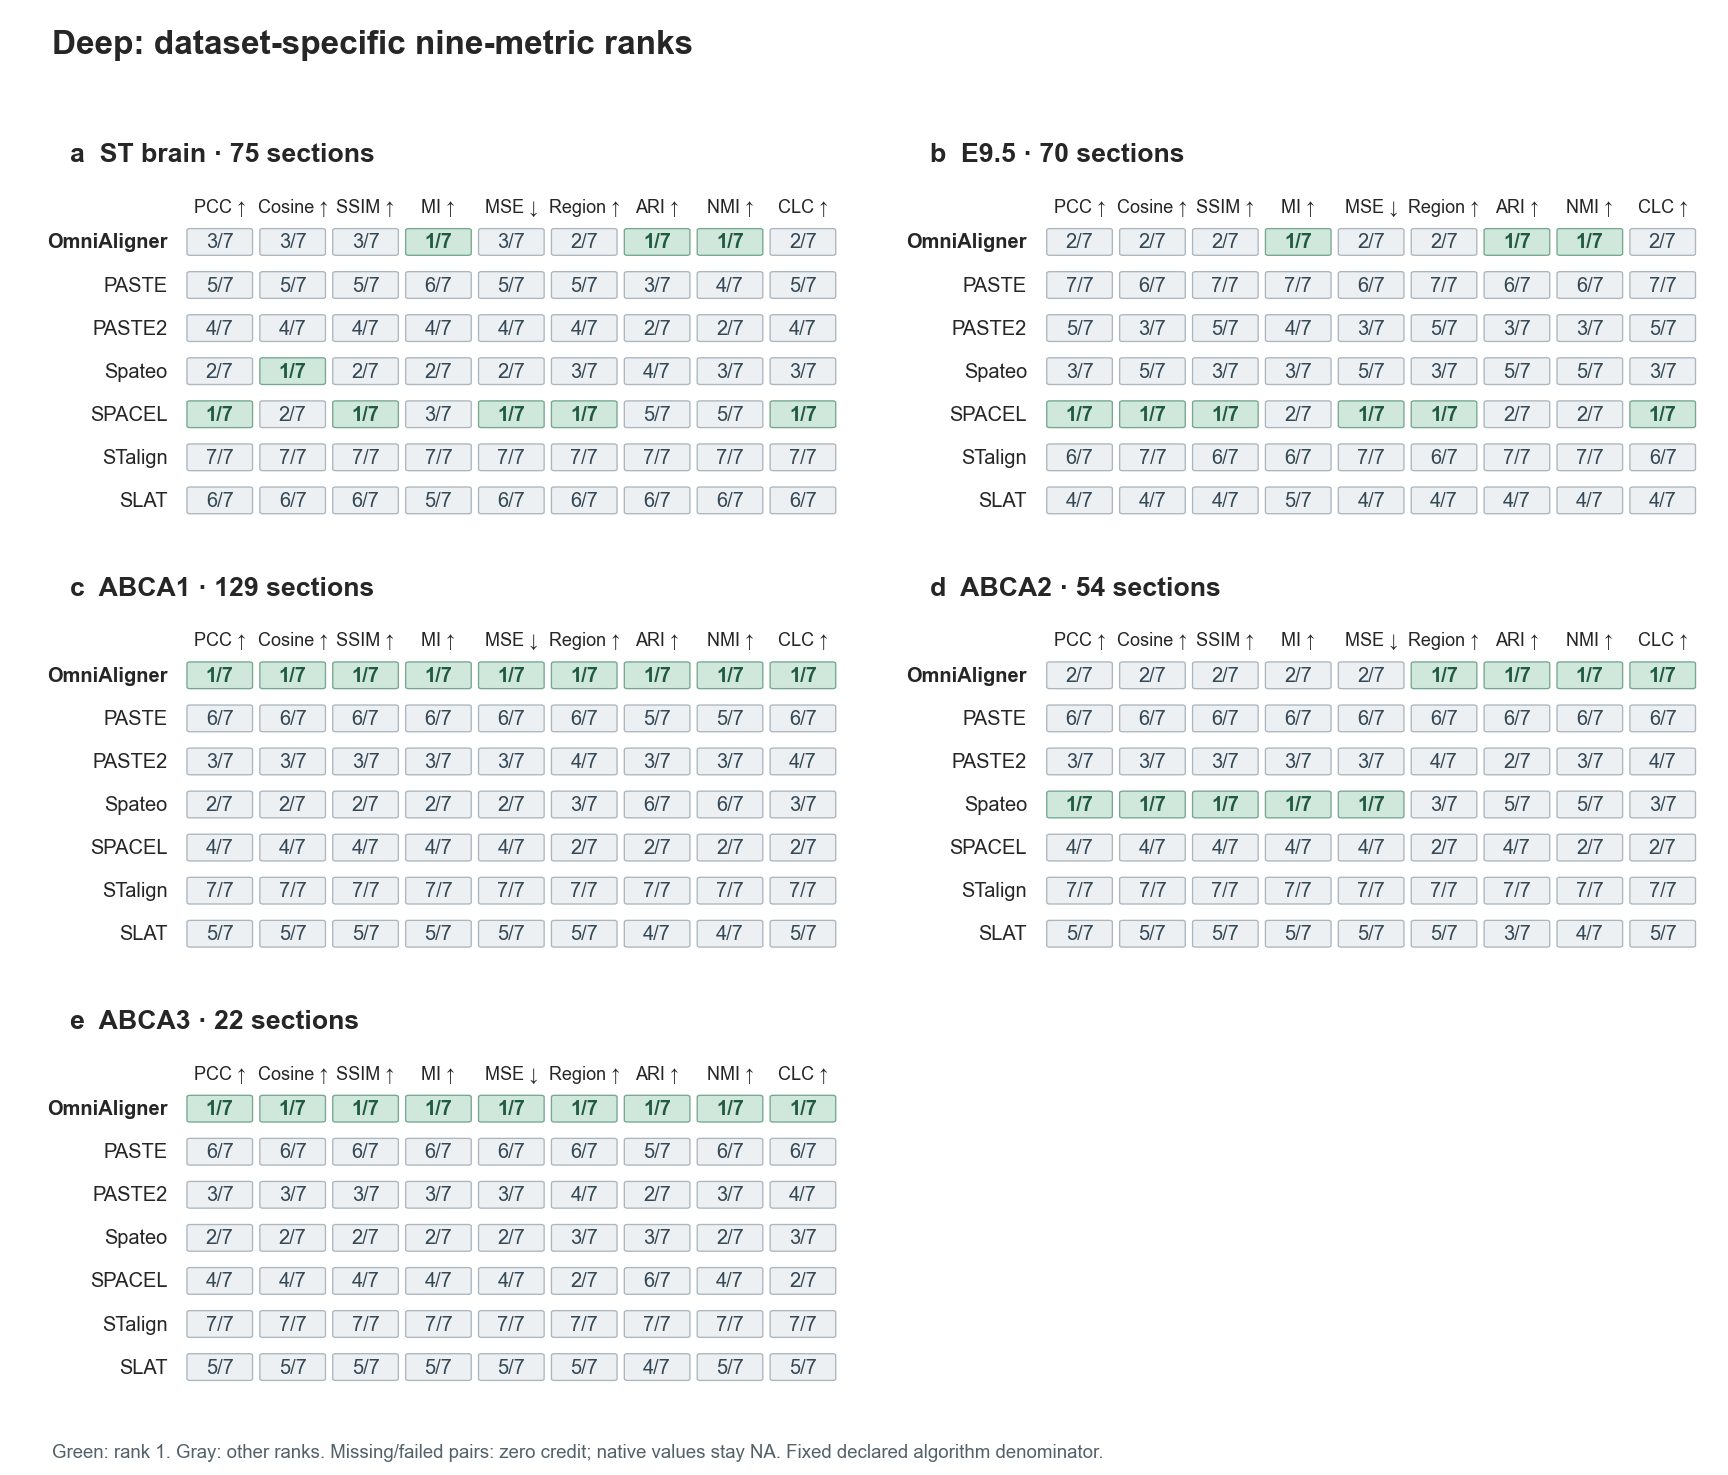

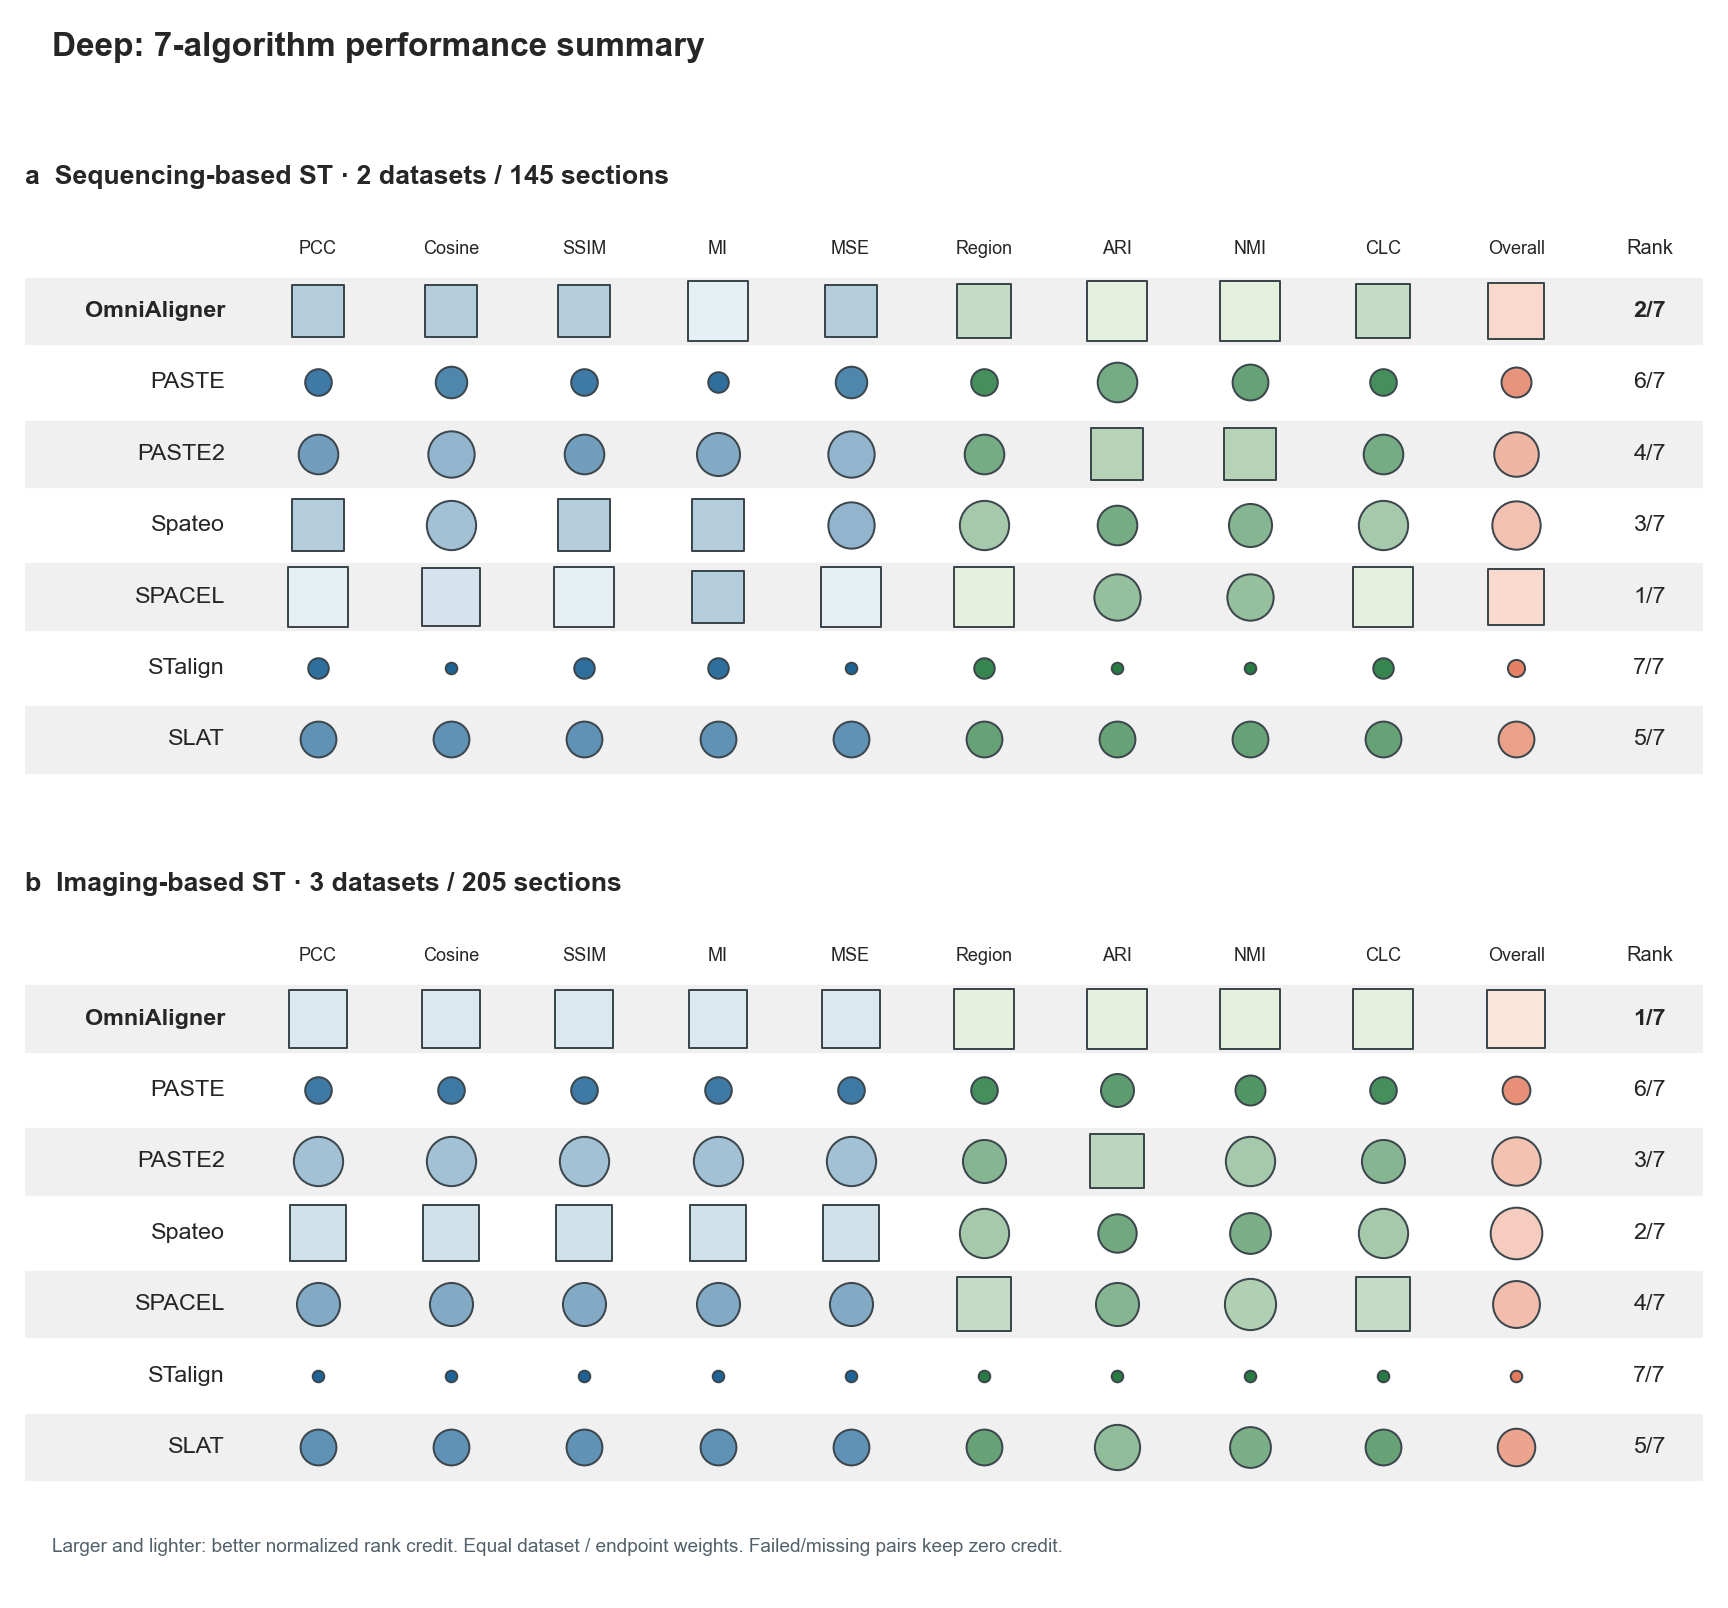

snapshot                                                                    af6732f680c24336
scope                                      Deep: current source-bound pair scores; explic...
expected_pair_metric_positions                                                         21735
observed_eligible_pair_metric_positions                                                21410
zero_credit_pair_metric_positions                                                        325
fresh_example_pairs                                                                        1
fresh_native_example_pairs                                                                 1
source_checksums_verified                                                               True
policy                                       expected_pair_weighted_native_metric_quality_v3
raw_missing_values_preserved                                                            True
no_partial_raw_mean_substitution                                      

In [19]:
CURRENT_OUTPUT = Path("deep_reproduced")
CURRENT_OUTPUT.mkdir(exist_ok=True)
pair_scores.to_csv(CURRENT_OUTPUT / "pair_scores_and_coverage.csv", index=False)
endpoint_scores.to_csv(CURRENT_OUTPUT / "nine_metric_scores_and_ranks.csv", index=False)
wide_raw.to_csv(CURRENT_OUTPUT / "native_complete_means.csv")
wide_scores.to_csv(CURRENT_OUTPUT / "nine_metric_coverage_adjusted_quality.csv")
status.to_csv(CURRENT_OUTPUT / "condition_status.csv", index=False)
draw_current_figures(endpoint_scores, COHORTS, ALGORITHMS, ALL_METRICS, CURRENT_OUTPUT, 'Deep', complete=bool(current_manifest["all_tasks_complete"]))
current_validation = dict(snapshot=current_manifest["snapshot"],
    scope=current_manifest["scope"], expected_pair_metric_positions=len(pair_scores),
    observed_eligible_pair_metric_positions=int(pair_scores.eligible.sum()),
    zero_credit_pair_metric_positions=int(pair_scores.penalized.sum()),
    fresh_example_pairs=len(fresh_examples), fresh_native_example_pairs=len(globals().get("fresh_native_examples", [])), source_checksums_verified=True,
    policy="expected_pair_weighted_native_metric_quality_v3", raw_missing_values_preserved=True,
    no_partial_raw_mean_substitution=True, algorithm_roster=ALGORITHMS, fixed_algorithm_denominator=N_ALGORITHMS,
    all_tasks_complete=bool(current_manifest["all_tasks_complete"]),
    pdf_fonttype=om.pl.plt.rcParams["pdf.fonttype"],
    font_family=om.pl.plt.rcParams["font.family"])
(CURRENT_OUTPUT / "VALIDATION.json").write_text(json.dumps(current_validation, indent=2)+"\n")
display(pd.Series(current_validation))